Connected to .venv (Python 3.13.2)

# TRENIRANJE XGBOOST MODELA

### Priprema modela

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import seaborn as sns

# Učitaj podatke
df = pd.read_csv("output/spojeni_podaci.csv")

# Pretvaranje datuma i dodavanje vremenskih značajki
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["dan_u_tjednu"] = df["Date"].dt.dayofweek
df["mjesec"] = df["Date"].dt.month
df["dan_u_godini"] = df["Date"].dt.dayofyear

# Odabir značajki i ciljne varijable
features = ["insolacija", "temperatura", "Peak Power (kW)"]
target = "PV Yield (kWh)"

# Uklanjanje redova s nedostajućim vrijednostima
df = df[features + [target]].dropna()

# Detekcija i uklanjanje outliera (IQR metoda)
Q1 = df[features + [target]].quantile(0.25)
Q3 = df[features + [target]].quantile(0.75)
IQR = Q3 - Q1
df = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]

# Korelacijska analiza (opcionalno za pregled)
correlation = df.corr()["PV Yield (kWh)"].sort_values(ascending=False)
print("Top značajke po korelaciji:\n", correlation)

# Priprema podataka za model
X = df[features]
y = df[target]

Top značajke po korelaciji:
 PV Yield (kWh)     1.000000
insolacija         0.907545
Peak Power (kW)    0.789445
temperatura        0.561178
Name: PV Yield (kWh), dtype: float64


### Inicijalizacija i treniranje modela

In [14]:
# Podjela na train/test skupove
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_params = {
    'learning_rate': 0.1,
    'max_depth': 2,
    'n_estimators': 50,
    'subsample': 1.0,
    'objective': 'reg:squarederror',
    'random_state': 42
}

# Treniranje XGBoost modela
model = xgb.XGBRegressor(**best_params)
model.fit(X_train, y_train)

# Predikcija
y_pred = model.predict(X_test)

### Evaluacija modela

In [15]:
# Evaluacija
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nEvaluacija modela:")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R²: {r2:.2f}")



Evaluacija modela:
MAE: 1.76
MSE: 5.90
R²: 0.92


### Vizaulizacija

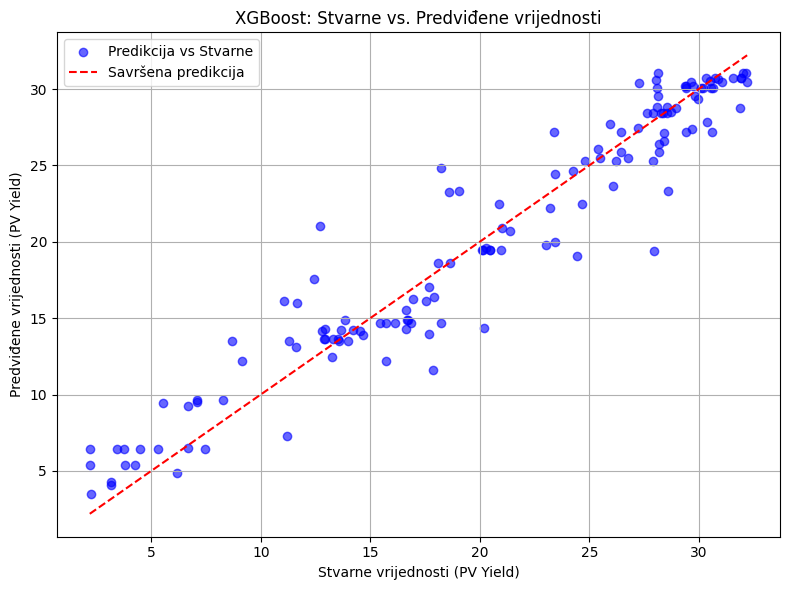

In [16]:
# Vizualizacija: scatter graf
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Predikcija vs Stvarne')
lims = [min(min(y_test), min(y_pred)), max(max(y_test), max(y_pred))]
plt.plot(lims, lims, 'r--', label='Savršena predikcija')
plt.xlabel("Stvarne vrijednosti (PV Yield)")
plt.ylabel("Predviđene vrijednosti (PV Yield)")
plt.title("XGBoost: Stvarne vs. Predviđene vrijednosti")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("grafovi/XGBoost.png")
plt.show()

## FINE-TUNING

### Trazenje najboljih vrijednosti parametara

In [17]:
from sklearn.model_selection import GridSearchCV
import joblib

# Parametri za isprobavanje
param_grid = {
    'n_estimators': [50, 200],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.07, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

# Inicijalizacija modela
xgb_model = xgb.XGBRegressor(random_state=42)

# GridSearch s 3-fold cross-validation
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid,
                           cv=3, scoring='r2', verbose=1, n_jobs=-1)

grid_search.fit(X_train, y_train)

# Najbolji parametri i novi model
print("Najbolji parametri:", grid_search.best_params_)
best_model = grid_search.best_estimator_

#spremanje najboljeg modela
joblib.dump(best_model, "output/xgboost_best_model.pkl")

# Evaluacija s najboljim modelom
y_pred_best = best_model.predict(X_test)
print("R² s najboljim modelom:", r2_score(y_test, y_pred_best))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Najbolji parametri: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 50, 'subsample': 1.0}
R² s najboljim modelom: 0.9243857487691228


### Feature importance

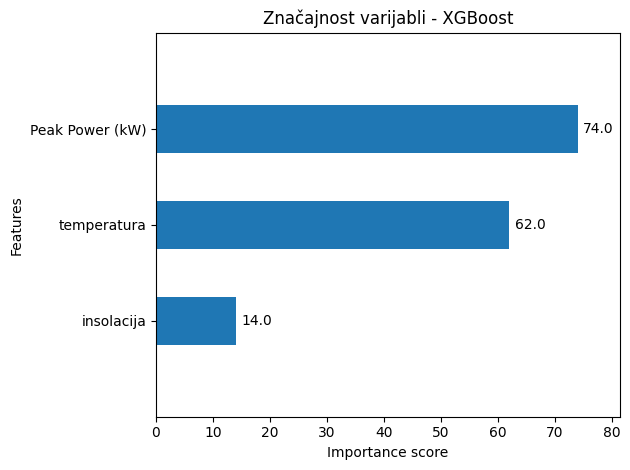

In [18]:
import matplotlib.pyplot as plt
xgb.plot_importance(model, importance_type="weight", show_values=True,
                    xlabel="Importance score", grid=False, height=0.5)
plt.title("Značajnost varijabli - XGBoost")
plt.yticks(ticks=range(len(features)), labels=features)  # koristi tvoju listu features
plt.tight_layout()
plt.savefig("grafovi/XGBoostfeauture_importance.png")
plt.show()